Dataset Shape: (569, 30)

Model Comparison:


,Model,Best CV Accuracy,Test Accuracy,Best Parameters
0,Logistic Regression,0.9824,0.9737,{'model__C': 0.1}
3,SVM,0.9758,0.9825,"{'model__C': 0.1, 'model__kernel': 'linear'}"
2,Random Forest,0.9626,0.9561,"{'model__max_depth': 10, 'model__n_estimators'..."
1,Decision Tree,0.9275,0.9386,"{'model__max_depth': 3, 'model__min_samples_sp..."



Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



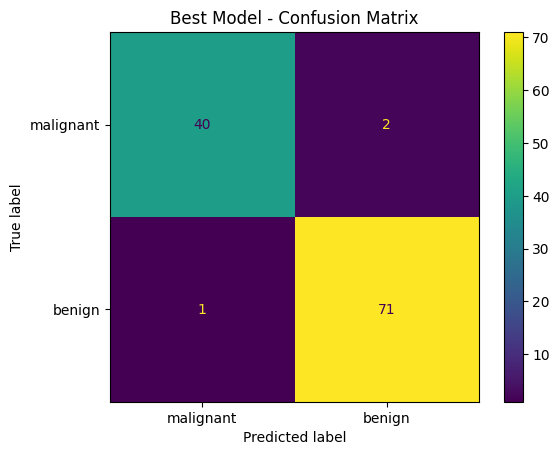

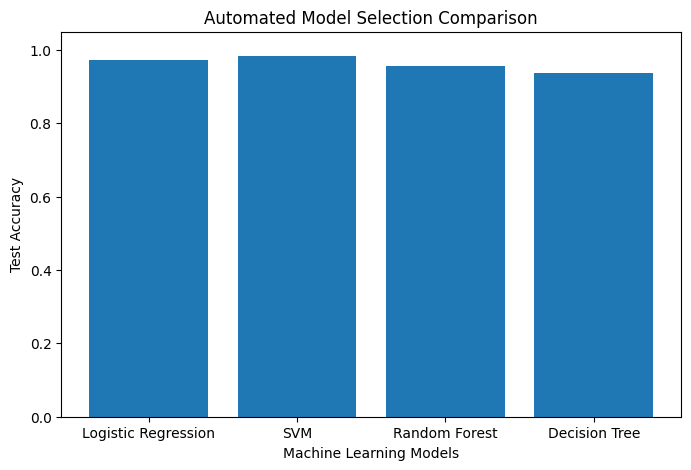

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1. Load Dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
print("Dataset Shape:", X.shape)

# 2. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# 3. Define Models and Hyperparameters
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000),{
            "model__C": [0.1, 1, 10]}),

    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),{
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_split": [2, 5]}),

    "Random Forest": (
        RandomForestClassifier(random_state=42),{
            "model__n_estimators": [50, 100],
            "model__max_depth": [5, 10, None]}),

    "SVM": (
        SVC(),{
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"]})
}

# 4. Automated Model Selection and Tuning
results = []
best_models = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, (estimator, params) in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)])

    search = GridSearchCV(
        pipeline,
        params,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1)

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_

    results.append({
        "Model": name,
        "Best CV Accuracy": search.best_score_,
        "Test Accuracy": accuracy_score(
            y_test, search.predict(X_test)),
        "Best Parameters": search.best_params_})

# 5. Compare Models
results_df = pd.DataFrame(results).sort_values(
    "Best CV Accuracy", ascending=False)
print("\nModel Comparison:")
display(results_df.round(4))

# 6. Select Best Model
best_name = results_df.iloc[0]["Model"]
best_model = best_models[best_name]
predictions = best_model.predict(X_test)

print("\nBest Model:", best_name)
print("\nClassification Report:")
print(classification_report(y_test, predictions,target_names=data.target_names))

# 7. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    display_labels=data.target_names)
plt.title("Best Model - Confusion Matrix")
plt.show()

# 8. Model Accuracy Comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Test Accuracy"])
plt.xlabel("Machine Learning Models")
plt.ylabel("Test Accuracy")
plt.title("Automated Model Selection Comparison")
plt.ylim(0, 1.05)
plt.show()